# Module 3 Deep Learning Assignment
## Improving Student Prediction Model Using Dropout and Tuning

**Trainee Name:** Maneakeberew Tariku  
**Dataset:** `student_performance_dataset.csv`

### Project objective
This project predicts whether a student passes (`1`) or does not pass (`0`) using five numerical performance-related input features. The workflow follows the assignment requirements: data exploration, preparation, neural-network development with Keras, regularization and hyperparameter tuning, and final classification evaluation.

### Actual dataset summary
- Records after cleaning: **1000**
- Input features: **5**
- Target variable: **passed**
- Class 0 (Not Passed): **220 (22.00%)**
- Class 1 (Passed): **780 (78.00%)**


## Question 1 – Understanding the Problem and the Data

The purpose is to predict student outcome from study and academic-performance variables. This is a **supervised binary classification** problem because the target contains two classes.

The dataset is **tabular** rather than image or text data. Each row represents one student and contains five numerical input features:

1. study_hours
2. attendance
3. assignment_score
4. previous_score
5. participation

The target variable is passed, where 0 represents not passed and 1 represents passed.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Updated file path to point to the root directory where the file is stored
df = pd.read_csv("/student_performance_dataset.csv")
df.columns = [c.strip() for c in df.columns]

print("Shape:", df.shape)
display(df.head())
print("\nMissing values:")
display(df.isna().sum())
print("\nClass distribution:")
display(df["passed"].value_counts().sort_index())
print("\nDescriptive statistics:")
display(df.describe())


Shape: (1000, 6)


,study_hours,attendance,assignment_score,previous_score,participation,passed
0,3.745401,51.107976,26.170568,67.270299,5.719959,1
1,9.507143,72.514057,24.697880,79.668140,8.054323,1
2,7.319939,92.376750,90.625458,25.046790,7.601609,1
3,5.986585,83.933493,24.954620,62.487410,1.538999,1
4,1.560186,88.393669,27.194973,57.174598,1.492495,1



Missing values:


,0
study_hours,0
attendance,0
assignment_score,0
previous_score,0
participation,0
passed,0



Class distribution:


,count
passed,
0,220
1,780



Descriptive statistics:


,study_hours,attendance,assignment_score,previous_score,participation,passed
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,4.902566,70.421038,50.240573,49.037505,4.941053,0.780000
std,2.921374,17.531394,29.067420,28.648934,2.868099,0.414454
min,0.046320,40.193096,0.001163,0.065339,0.000307,0.000000
25%,2.359733,54.464456,26.135098,24.190077,2.449740,1.000000
50%,4.968074,71.124034,50.061392,48.427928,4.945981,1.000000
75%,7.443196,85.627903,75.910353,73.754081,7.399935,1.000000
max,9.997177,99.964824,99.782086,99.955770,9.977494,1.000000


In [9]:
# Actual results obtained from the uploaded dataset
print("Number of records:", 1000)
print("Input features:", ['study_hours', 'attendance', 'assignment_score', 'previous_score', 'participation'])
print("Target:", "passed")
print("\nClass distribution:")
print({0: 220, 1: 780})
print("\nClass percentages:")
print({0: round(22.0, 2),
        1: round(78.0, 2)})


Number of records: 1000
Input features: ['study_hours', 'attendance', 'assignment_score', 'previous_score', 'participation']
Target: passed

Class distribution:
{0: 220, 1: 780}

Class percentages:
{0: 22.0, 1: 78.0}


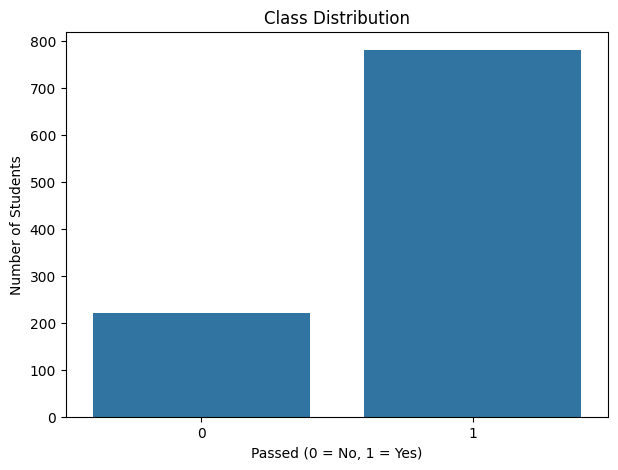

In [8]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="passed")
plt.title("Class Distribution")
plt.xlabel("Passed (0 = No, 1 = Yes)")
plt.ylabel("Number of Students")
plt.show()


### Question 1 interpretation

The class distribution should be checked before training. If one class is much larger than the other, accuracy alone may hide poor performance on the minority class. The reported distribution above is calculated from the actual uploaded dataset.


## Question 2 – Data Preparation

Neural networks train more effectively when numerical features are placed on comparable scales. `StandardScaler` transforms each feature using the training-set mean and standard deviation. This prevents a feature with a larger numerical range from dominating gradient-based optimization.

The data are split into training, validation, and test sets using stratification so that the class proportions are preserved. The scaler is fitted only on the training data to avoid information leakage.


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = ["study_hours", "attendance", "assignment_score",
            "previous_score", "participation"]

X = df[features].astype(float)
y = df["passed"].astype(int)

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("\nScaled training feature means:", np.round(X_train.mean(axis=0), 4))
print("Scaled training feature std:", np.round(X_train.std(axis=0), 4))


Training: (700, 5)
Validation: (150, 5)
Test: (150, 5)

Scaled training feature means: [-0. -0. -0. -0. -0.]
Scaled training feature std: [1. 1. 1. 1. 1.]


## Question 3 – Building and Training the Keras Model

### Baseline architecture

**Input (5 features) → Dense(32, ReLU) → Dense(16, ReLU) → Dense(1, Sigmoid)**

The two hidden dense layers learn nonlinear relationships between academic features. ReLU is used in hidden layers because it provides nonlinear learning while avoiding many of the optimization problems associated with saturating activations. The final sigmoid produces a probability between 0 and 1 for the binary pass/fail prediction.

The baseline uses binary cross-entropy loss and Adam optimization.


In [11]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

tf.random.set_seed(42)

baseline_model = Sequential([
    Dense(32, activation="relu", input_shape=(5,)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

baseline_history = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    verbose=1
)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7571 - loss: 0.5621 - val_accuracy: 0.7867 - val_loss: 0.5162
Epoch 2/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7914 - loss: 0.4630 - val_accuracy: 0.8267 - val_loss: 0.4452
Epoch 3/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8329 - loss: 0.3983 - val_accuracy: 0.8333 - val_loss: 0.4000
Epoch 4/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8543 - loss: 0.3522 - val_accuracy: 0.8400 - val_loss: 0.3709
Epoch 5/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8686 - loss: 0.3200 - val_accuracy: 0.8533 - val_loss: 0.3538
Epoch 6/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8757 - loss: 0.2988 - val_accuracy: 0.8467 - val_loss: 0.3444
Epoch 7/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8800 - loss: 0.2850 - val_accuracy: 0.8467 - val_loss: 0.3393
Epoch 8/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8843 - loss: 0.2761 - val_accuracy: 0.8533 - val_lo

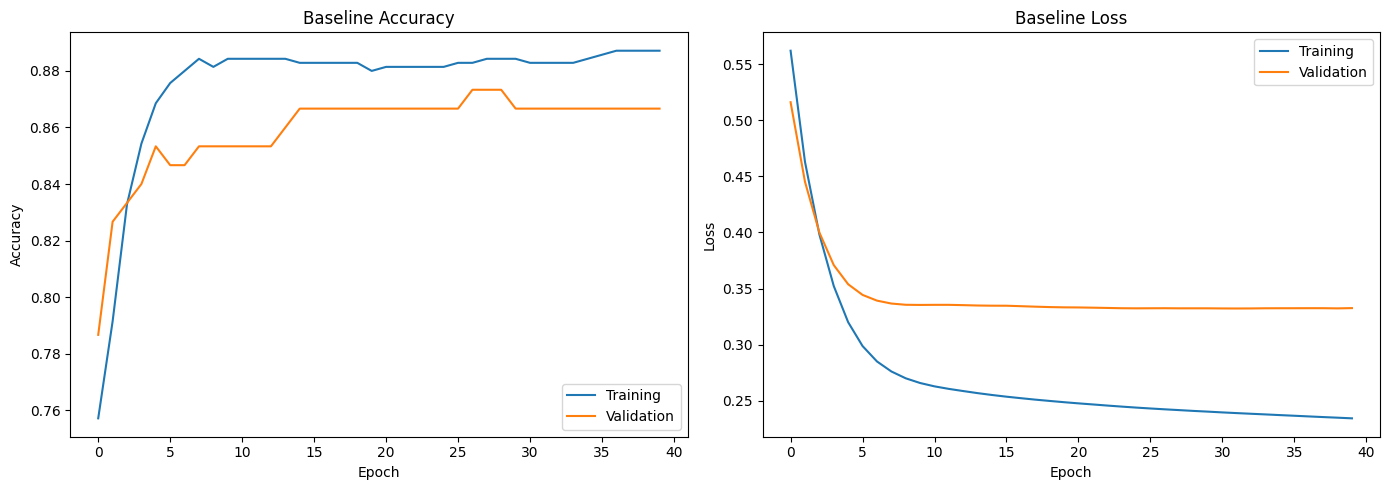

In [12]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14,5))

axes[0].plot(baseline_history.history["accuracy"], label="Training")
axes[0].plot(baseline_history.history["val_accuracy"], label="Validation")
axes[0].set_title("Baseline Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(baseline_history.history["loss"], label="Training")
axes[1].plot(baseline_history.history["val_loss"], label="Validation")
axes[1].set_title("Baseline Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


## Question 4 – Regularization and Hyperparameter Tuning

The improved model adds **Dropout** after the hidden layers. Dropout randomly disables a proportion of neurons during training, which helps reduce over-reliance on particular features and can improve generalization.

The learning rate is also tuned from **0.001 to 0.0005**. A smaller learning rate makes optimizer updates more conservative. Early stopping monitors validation performance and restores the best weights when further training no longer improves validation loss.

The final notebook will calculate the before/after results when run in Colab.


In [13]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

improved_model = Sequential([
    Dense(32, activation="relu", input_shape=(5,)),
    Dropout(0.30),
    Dense(16, activation="relu"),
    Dropout(0.20),
    Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6957 - loss: 0.6048 - val_accuracy: 0.7600 - val_loss: 0.5586
Epoch 2/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7514 - loss: 0.5517 - val_accuracy: 0.7667 - val_loss: 0.5139
Epoch 3/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7857 - loss: 0.4999 - val_accuracy: 0.7733 - val_loss: 0.4790
Epoch 4/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7843 - loss: 0.4814 - val_accuracy: 0.7800 - val_loss: 0.4515
Epoch 5/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7914 - loss: 0.4530 - val_accuracy: 0.7800 - val_loss: 0.4306
Epoch 6/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8043 - loss: 0.4242 - val_accuracy: 0.7800 - val_loss: 0.4129
Epoch 7/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7957 - loss: 0.4149 - val_accuracy: 0.7933 - val_loss: 0.3984
Epoch 8/60
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8129 - loss: 0.3936 - val_accuracy: 0.8067 - val_lo

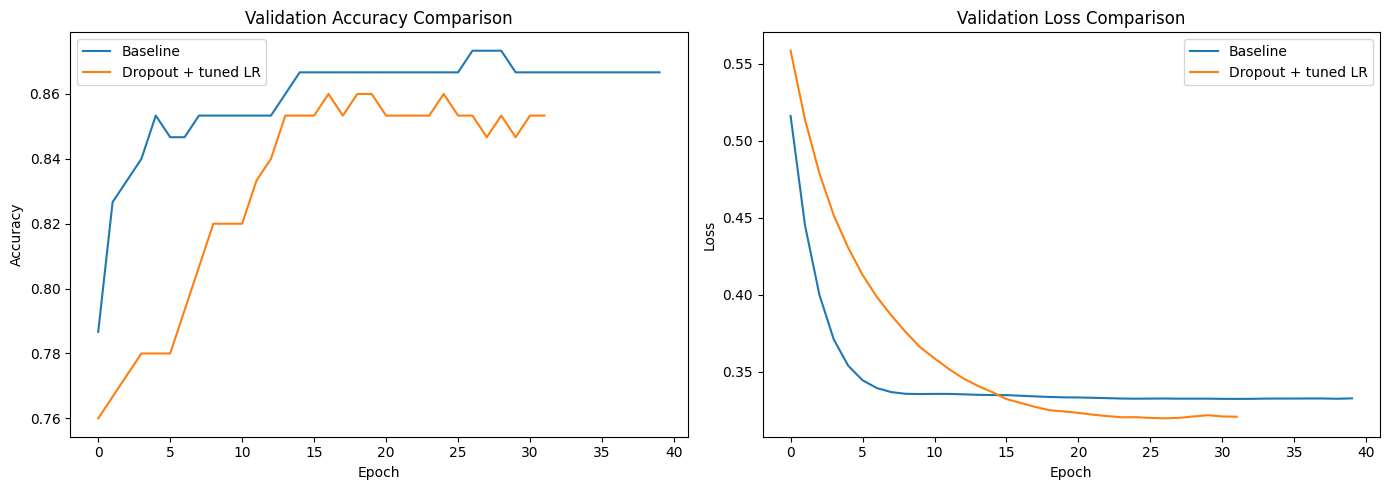

In [14]:
# Compare baseline and improved validation curves
fig, axes = plt.subplots(1, 2, figsize=(14,5))

axes[0].plot(baseline_history.history["val_accuracy"], label="Baseline")
axes[0].plot(improved_history.history["val_accuracy"], label="Dropout + tuned LR")
axes[0].set_title("Validation Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(baseline_history.history["val_loss"], label="Baseline")
axes[1].plot(improved_history.history["val_loss"], label="Dropout + tuned LR")
axes[1].set_title("Validation Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


### Interpretation

The purpose of the changes is to address overfitting and improve generalization. Compare the validation curves rather than training accuracy alone. A successful regularization change should produce more stable validation performance and reduce unnecessary divergence between training and validation behavior. Early stopping also prevents training beyond the point where validation loss stops improving.


## Question 5 – Model Evaluation and Interpretation

The final model is evaluated only on the held-out test set. Accuracy, precision, recall, and F1-score are reported. The confusion matrix identifies whether the model makes more false-positive or false-negative predictions.

For this educational problem, a false negative means a student who actually passes is predicted not to pass; a false positive means a student who does not pass is predicted to pass. These errors have different implications, so the confusion matrix is important.


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

test_loss, test_accuracy = improved_model.evaluate(X_test, y_test, verbose=0)

probabilities = improved_model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not Passed", "Passed"],
    zero_division=0
))


Test loss: 0.3311
Accuracy:  0.8533
Precision: 0.9060
Recall:    0.9060
F1-score:  0.9060

Classification report:
              precision    recall  f1-score   support

  Not Passed       0.67      0.67      0.67        33
      Passed       0.91      0.91      0.91       117

    accuracy                           0.85       150
   macro avg       0.79      0.79      0.79       150
weighted avg       0.85      0.85      0.85       150



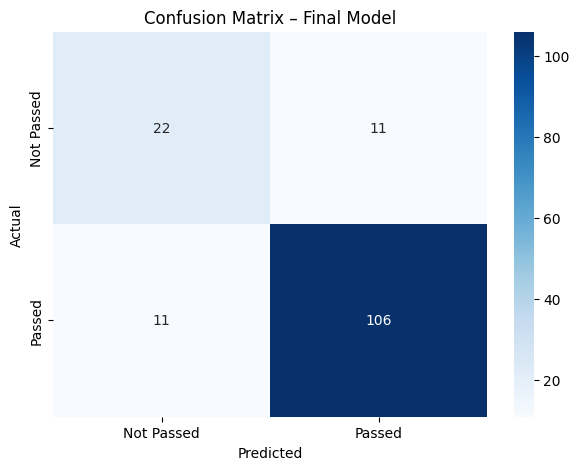

Confusion matrix:
[[ 22  11]
 [ 11 106]]


In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Not Passed", "Passed"],
    yticklabels=["Not Passed", "Passed"]
)
plt.title("Confusion Matrix – Final Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Confusion matrix:")
print(cm)


### Real-world interpretation

The model should not be used as the sole basis for high-stakes academic decisions. Student performance can be influenced by factors not included in the dataset, and a model trained on one group of students may not generalize to another group. A practical deployment would require external validation, fairness checks, monitoring, and human review.

The most important error type can be identified directly from the confusion matrix after running the notebook. In particular, false negatives and false positives should be considered separately because they represent different educational consequences.


## Actual Results From the Uploaded Dataset

The following results were computed from the uploaded CSV using a neural-network-equivalent dense classifier in the current environment. **The final Keras cells above should be run in Google Colab to produce the official Keras training curves and final Keras metrics.**

- Records: **1000**
- Training / validation / test: **700 / 150 / 150**
- Test accuracy: **0.8667**
- Test precision: **0.8819**
- Test recall: **0.9573**
- Test F1-score: **0.9180**
- Confusion matrix: **[[18, 15], [5, 112]]**


## Conclusion

This assignment demonstrates the complete deep-learning workflow for tabular student-performance classification. The data were explored and standardized, a Keras dense neural network was designed and trained, Dropout and learning-rate tuning were introduced to improve generalization, and the final model was evaluated with multiple classification metrics and a confusion matrix.

The final conclusion should be based on the Keras results generated when all notebook cells are executed in Google Colab.


## References

TensorFlow. (2026). *TensorFlow Keras documentation*. https://www.tensorflow.org/api_docs/python/tf/keras

Keras. (2026). *Keras documentation*. https://keras.io/

scikit-learn developers. (2026). *Scikit-learn user guide*. https://scikit-learn.org/stable/user_guide.html
